<a href="https://colab.research.google.com/github/xebecebex/transformers_cookbook/blob/main/AI_WRKSHP_Series2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

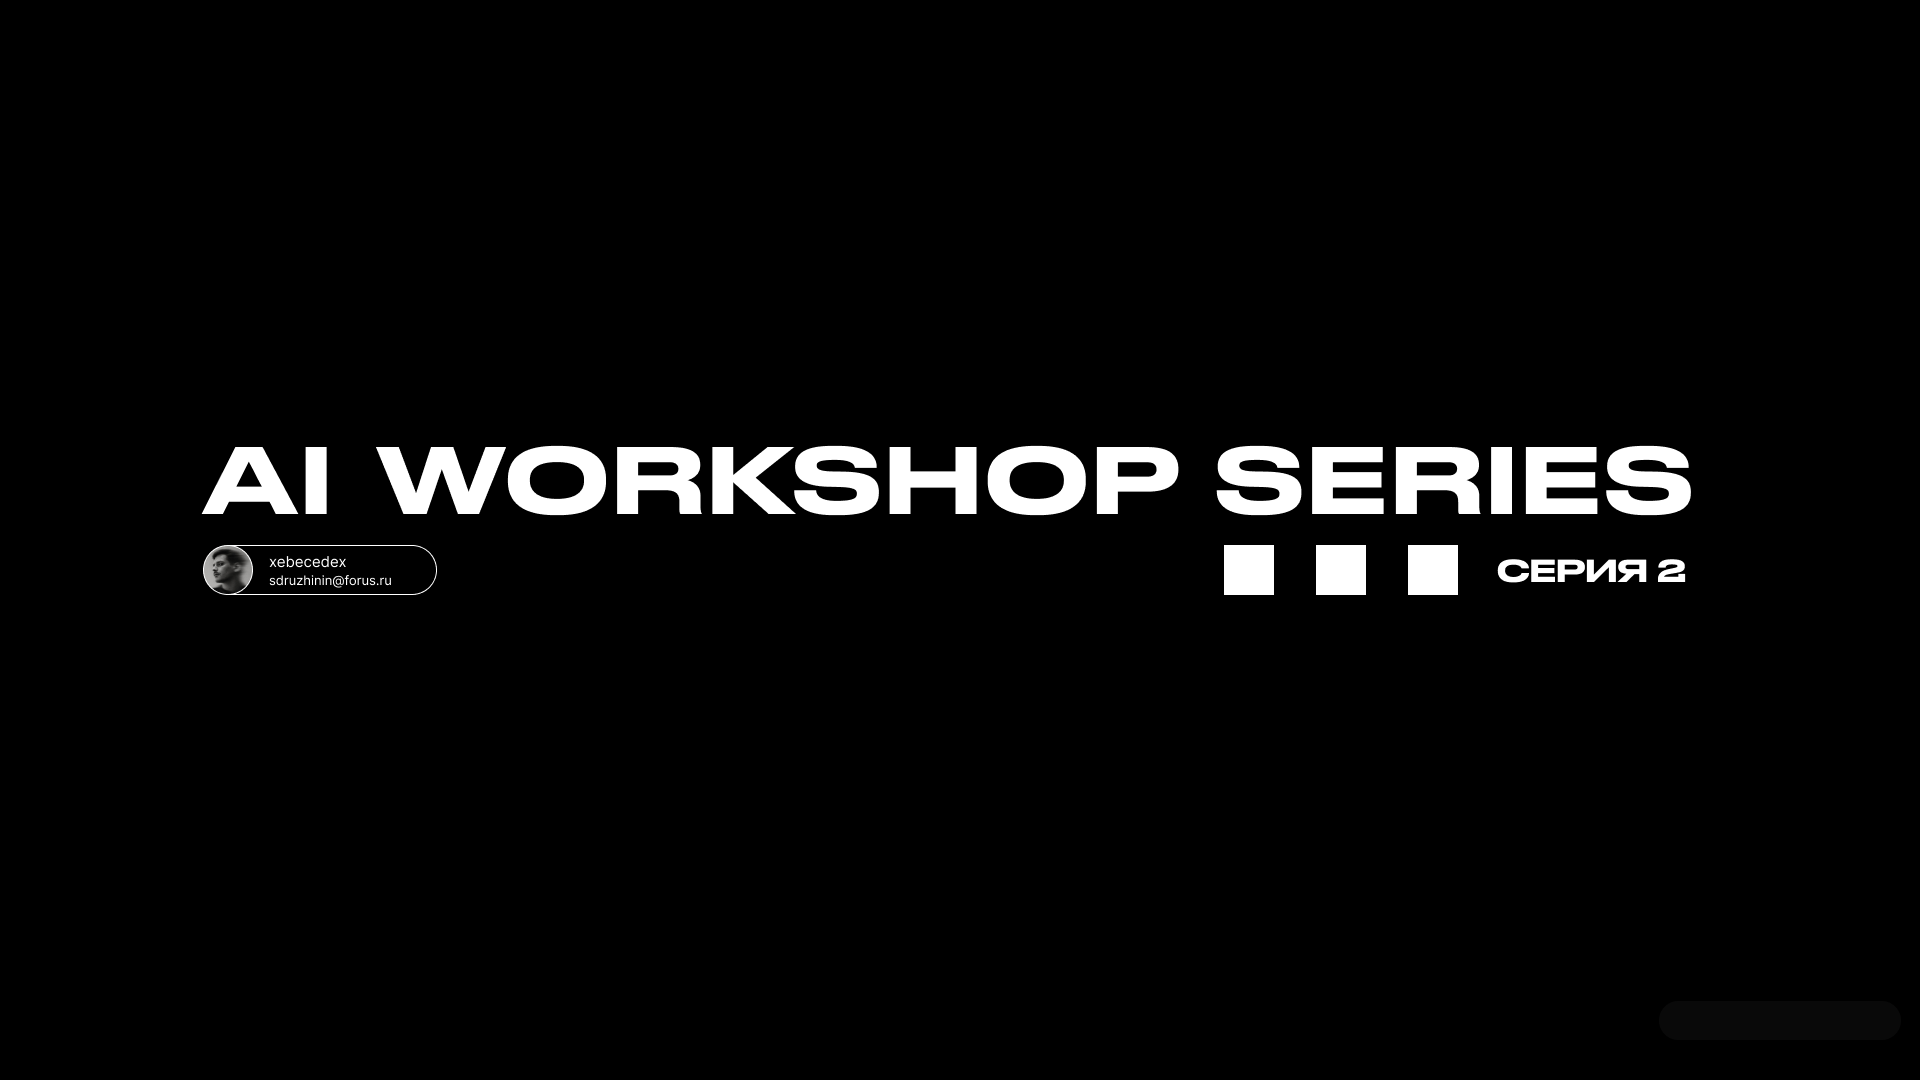

В рамках AI WORKSHOP SERIES (Серия 1) мы обсудили:
- Что такое трансформер;
- Что такое инференс;
- Что такое харнесс;
- Что такое токенизация.
 Вот ссылка на презентацию: https://drive.google.com/file/d/1HGKuRG8prrQ3ASbsgHz2JRQy9_pbv21m/view?usp=sharing



---



 Теперь нам надо разобраться с этим на практике. Разбираемая нами тема - использование локальных моделей в задачах анализа и разработки.

 Для запуска локальных моделей используются различного рода движки, вот основные из них:
 1) Ollama;
 2) Llama.cpp;
 3) LMStudio;
 4) MLX.

Перечисленные выше движки (инференс моделей) предназначены для работы в "домашних" условиях. Для запуска на серверном оборудовании уже используются более мощные и адаптированные под GPU-кластер движки (vLLM и TensorRT-LLM).

Хотя многие исследователи старательно ищут способ сместить фокус с промышленного железа в сторону более приземленного (домашнего). Но это не тема нашей серии.

---

1) Ollama (https://ollama.com/) - Это высокоуровневое приложение и REST API-сервер для запуска больших языковых моделей (LLM). Имеет собственный каталог моделей, автозагрузку и удобный клиент под разные ОС.
На ПК с NVIDIA (например, RTX 4060) может уступать голому llama.cpp. На Mac последние версии Ollama задействуют движок MLX, но с небольшой прослойкой оверхеда (но все равно уступает MLX, Apple же!). Предельная простота, интеграция с сотнями клиентских программ (Chatbot UI, LibreChat, Continue).

2) MLX (https://ml-explore.github.io/mlx/build/html/index.html)- Фреймворк машинного обучения, разработанный специально под архитектуру Apple Silicon (M-серии) с концепцией Unified Memory (унифицированной памяти). Используется в качестве локального инференса моделей.

3) lamma.cpp (https://llama-cpp.com/) - Стандарт локального инференса на чистом C/C++.Работает абсолютно везде — на слабых процессорах (CPU), видеокартах NVIDIA (CUDA), AMD (Vulkan / ROCm) и Apple Silicon (Metal). Использует формат GGUF. Отлично справляется с параллельной обработкой промптов. Максимальная переносимость, гибкость, поддержка экзотических видеокарт и процессоров, огромная экосистема.На macOS генерация токенов уступает нативному MLX, а настройка требует больше времени, чем запуск одной командой в Ollama.

4) LMStudio (https://lmstudio.ai/) - Автономная визуальная среда. Внутри LM Studio работает движок llama.cpp, но пользователю не нужно писать команды в терминале — все управляется кнопками и ползунками. В приложение встроен удобный поиск по Hugging Face. Мы можем найти любую модель, выбрать нужный уровень квантования  и скачать ее в один клик. Так как внутри используется llama.cpp, скорость работы отличная. Приложение автоматически определяет железо и позволяет гибко настроить распределение слоев модели: часть отправить на видеокарту (GPU Offload), а часть оставить в оперативной памяти (CPU). Закрытый исходный код (в отличие от Ollama, MLX и llama.cpp). Потребляет чуть больше ресурсов компьютера из-за графической оболочки. Нет CLI-интерфейса для автоматизации в скриптах (ориентировано на управление мышкой).

Далее, ознакомившись с основными движками запуска и исполнения LLM, вы можете самостоятельно установить один из движков (для Windows рекомендуется использовать ollama или LMStudio. У кого Linux (Ubuntu/Debian), то ollama или llama.cpp, у кого Aplle Silicon - соответственно, MLX).

Для того, чтобы понимать на базовом уровне - какая модель подойдет под ваши аппартные возможност, можете воспользоваться https://github.com/AlexsJones/llmfit (доступен для Mac, Linux, Windows).

---

В рамках этого урока, мы не только научимся ставить и оценивать локальные модели, но и работать с библиотекой Transformers.

Библиотека Transformers была разработана командой Hugging Face. Ее основные возможности:
- Загрузка готовых моделей: Позволяет в несколько строк кода скачивать и запускать десятки тысяч готовых нейросетей из официального репозитория Hugging Face Hub.
- Готовый пайплайн (pipeline): Дает универсальный инструмент для быстрого решения прикладных задач (генерация текста, классификация, суммаризация, перевод, анализ тональности, ответы на вопросы) без долгой настройки кода.
- Дообучение (Fine-tuning): Позволяет адаптировать массивные базовые модели под специфические задачи (доменная специализация, которую мы рассматривали в рамках первой серии нашего воркшопа).
- Экспорт и оптимизация: Позволяет конвертировать модели в форматы вроде ONNX или TorchScript для быстрого запуска в продакшене

Вам ничего устанавливать не нужно, потому что мы используем notebook (Colab), исполнение кода производится на серверах Google.

# Использование локального инференса моделей

Мы будем рассматривать в качестве локального инференса моделей движок ollama - так как он легковесный и наиболее распространен в кросс-платформенных средах.

### 1. Ollama local inference model

Установка Ollama для Windows:
1) Перейти на https://ollama.com/download/windows
2) Нажмите на кнопку "Download manually". Будет скачан .exe-файл. Далее все, что потребуется - это установить.
3) После установки, запускаем ollama. После запуска мы можем выбрать конкретную модель. Однако не торопитесь с выбором, мы к этому еще вернемся (ведь нам нужно понять, какая точно модель подойдет под требуемые аппаратные возможности).

### 2. Perfomance analysis

Для понимания того, какая модель лучше всего подходит для локального инференса и выполнения задач, необходимо использовать улититу llmfit (https://github.com/AlexsJones/llmfit) - она устанавливается на все ОС.

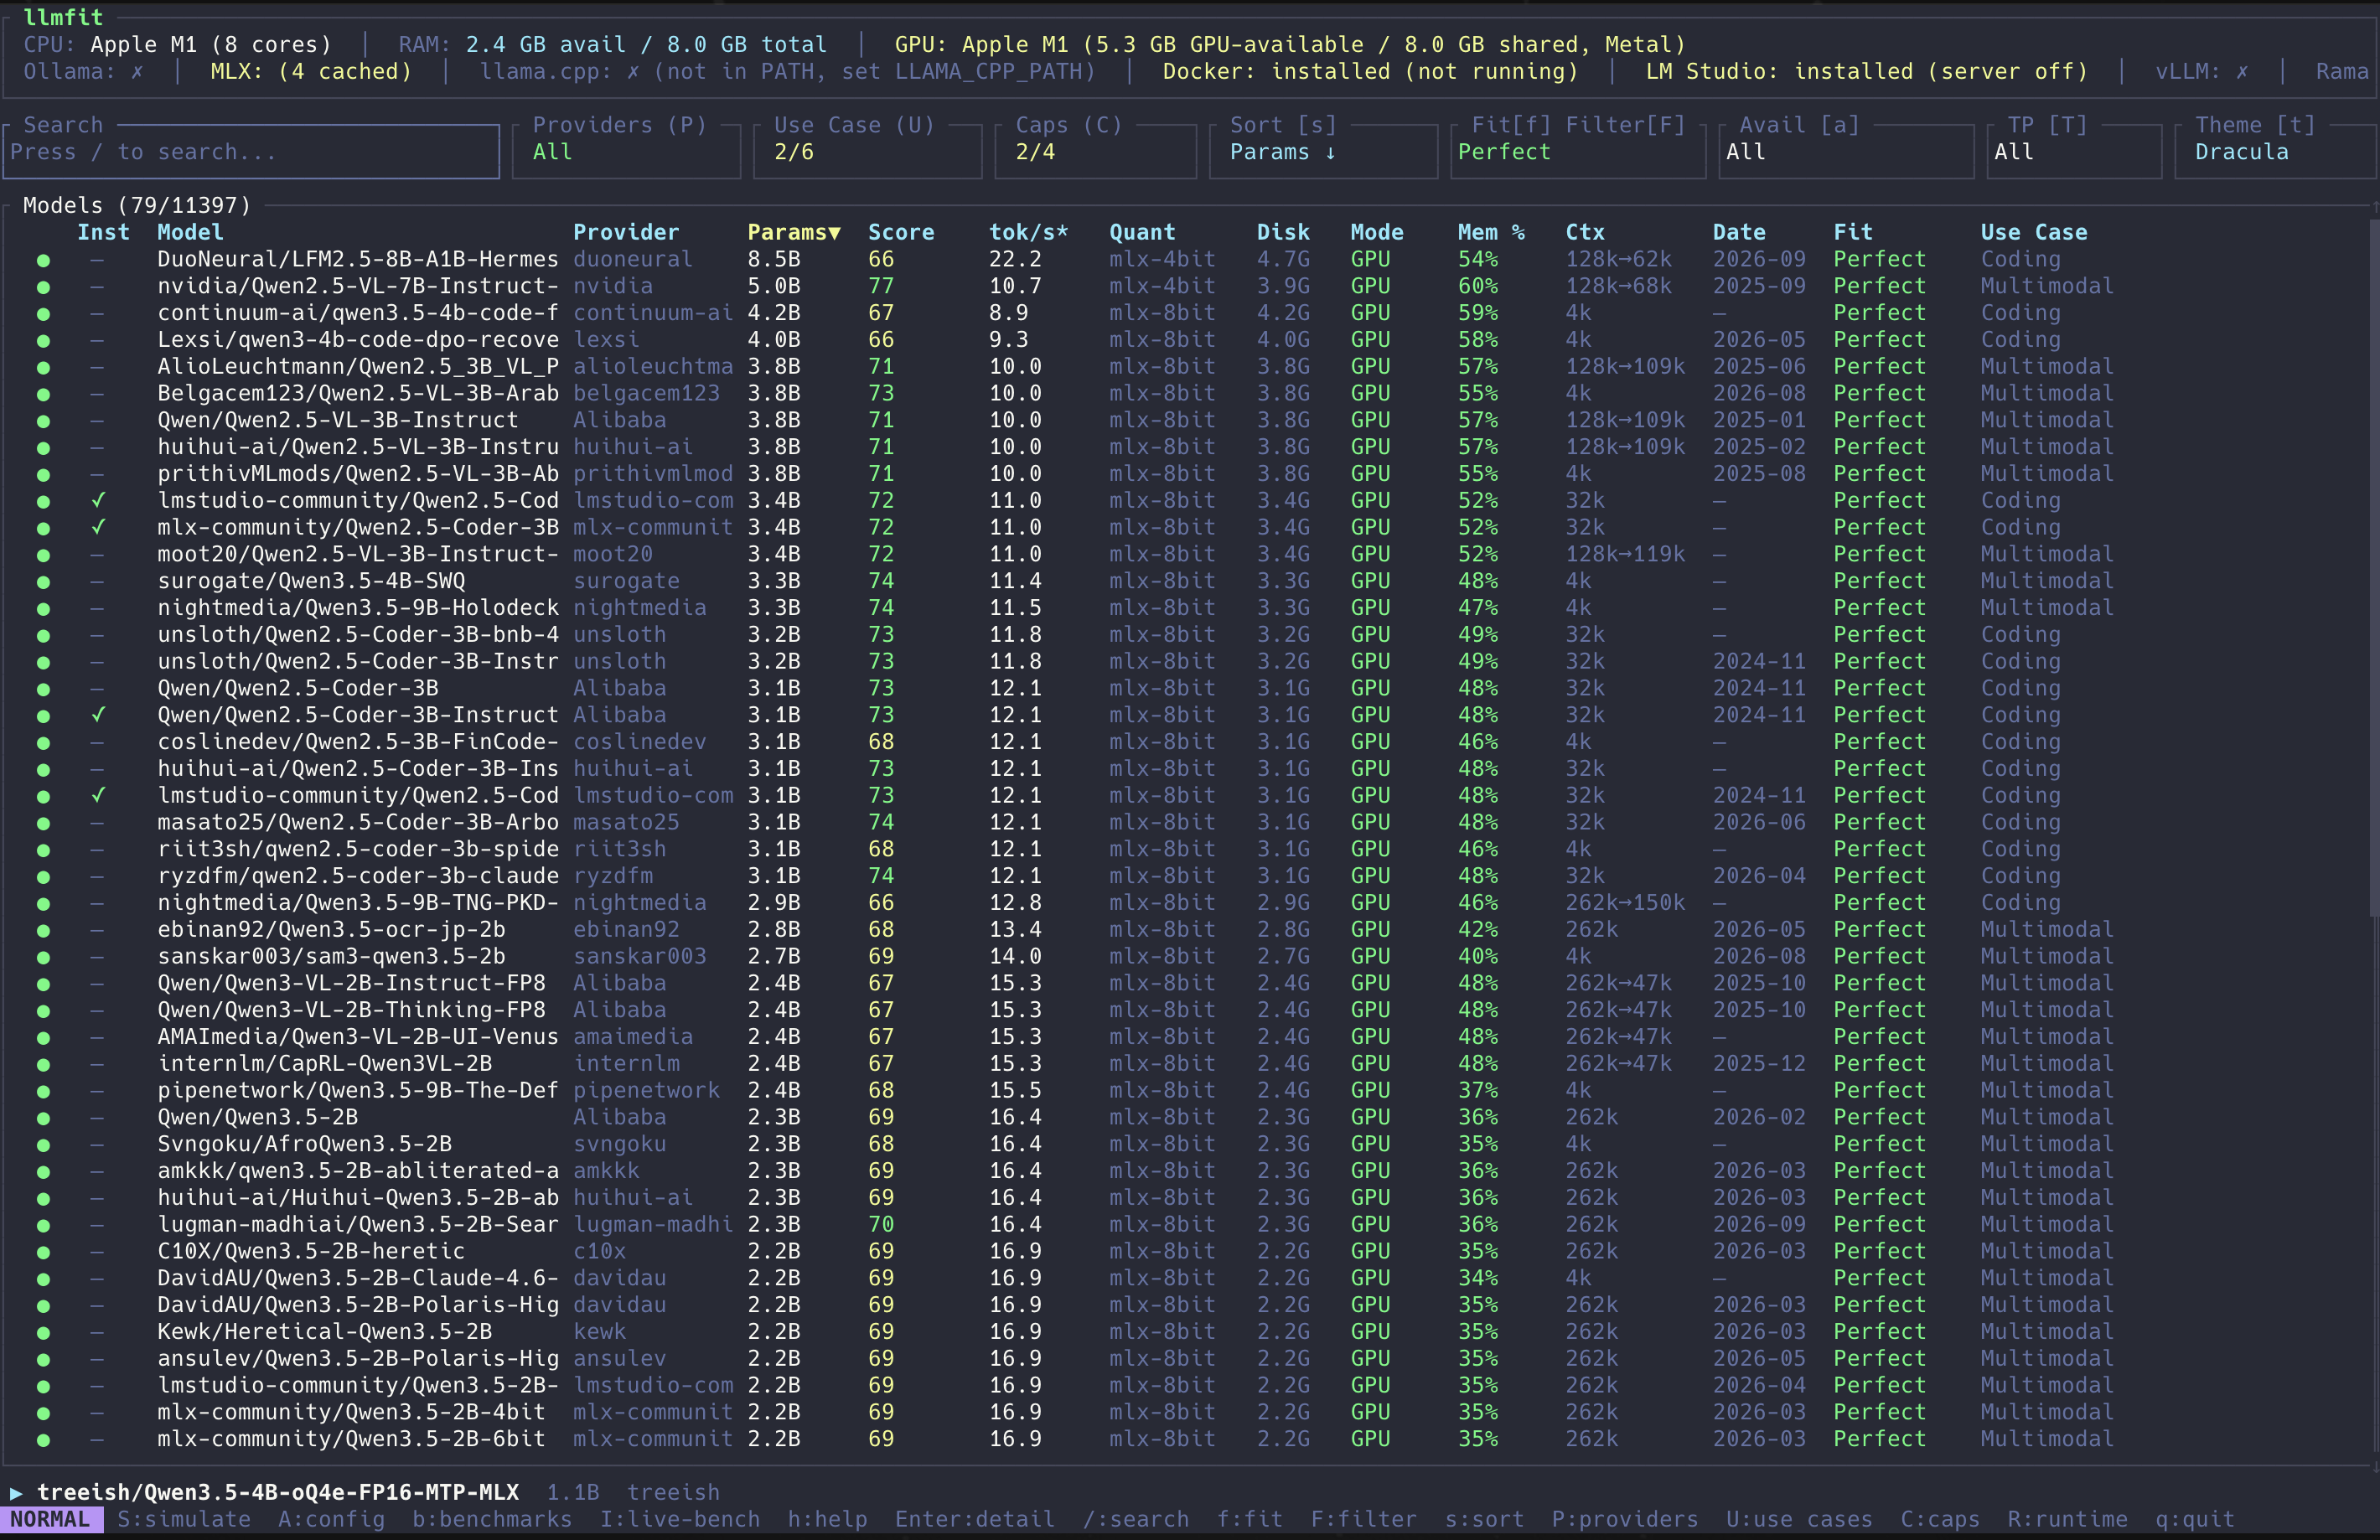



В llmfit вы можете увидеть какие модели, могут Вам подойти. В основном, все представленные модели уже есть на ollama/models (https://ollama.com/search?c=local&s=8).

Если у Вас уже установленна ollama, то можете установить эту модель: 1) Через командную строку ollama pull <ИдентификаторМодели> (ollama pull qwen3.5:4b); 2) Через графический интерфейс.

Запуск модели осуществляется через команду ollama run <ИдентификаторМодели>.

Эта команда вызовет терминальное окно с диалогом. В целом, можете ввести любой запрос, чтобы увидеть результат.


Оценка метрик производится штатно в ollama, но требуется написание скриптов на Python (так как у меня mac, а у большинства Windows, да и еще рабочая техника от Форус, то эксперементы ставить не будем. У кого личная техника - можете написать в личные сообщения).


А вот самое интересное - это библиотека Transformers, которую мы можем использовать прямо в этом нотбуке без необходимости установок на локальном ПК всех приблуд (собирательное слово для обозначения модулей, ПО, библиотек).

## Transformers library from Hugging Face

Назначение библиотеки вы можете прочитать выше, в самом начальном блоке.

Установливать ничего не нужно, она уже предустановлена в рамках виртуального пространства настоящего нотбука.

Все, что нужно - это запуск кода внутри этого нотбука (нажать на Play).

Сначала мы будем запускать маленькие модели, которые не относятся к классу LLM или SML. Нам нужно понять принцип работы этой библиотеки.

Код ниже устанавливает делает следующее:

- transformers: библиотека от Hugging Face, которая предоставляет предобученные модели (например, BERT, GPT, Llama, T5) и инструменты для их дообучения и запуска.
- datasets: библиотека для быстрой загрузки, обработки и управления огромными текстовыми, аудио- и визуальными наборами данных.
- sentencepiece: токенизатор, который разбивает текст на подслова (subwords). Он необходим для корректной работы многих современных языковых моделей (например, Llama или T5).
- datatrove[multilingual]: библиотека от Hugging Face для крупномасштабной фильтрации, очистки и обработки сырых текстовых данных. Синтаксис [multilingual] указывает, что вместе с базовой библиотекой нужно установить дополнительные зависимости для работы с многоязычными текстами.

In [ ]:
pip install transformers datasets sentencepiece 'datatrove[multilingual]'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.5/35.5 MB 14.8 MB/s  0:00:02
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of urduhack to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of urduhack to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 45.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

А вот этот код устанавливает библиотеку для фильтрации, очистки, токенизации и дедупликации текстовых данных в огромных масштабах (предыдущая команда устанавливала только минимальный набор зависимостей).

In [ ]:
pip install datatrove

Ниже мы используем pipeline - компонент, который позволяет прогонять различные сценарии использования той или иной модели из HuggingFace Hub.

In [ ]:
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
classifier("Я не успеваю закончить свои пет-проекты. Некоторые из этих проектов используются для исследовательских целей")

О чем этот код ?
Первым делом, мы импортируем модуль pipeline из библиотеки Transformers. Эта библиотека была разработана командой HuggingFace для задач, связанных с архитектурой трансформера. С помощью этой библиотеки мы можем анализировать поведение отдельной модели (при условии, что она имеется в HuggingFace Hub - открытом реестре моделей машинного и глубокого обучения).


Выше код вернул результат: POSITIVE. Я ему передал отрицательные параметры (я ведь не успеваю закончить пет-проекты...) - в чем же здесь позитивного ? Дело в том, что данная модель sentiment-analysis рассчитывает вероятность (63% составляет вероятность, что мое сообщение является позитивной конатации).

А вот ниже мы проводим оценку токенизатора той или иной модели. Мы выполним замер (оценку) токенизации.


In [ ]:
# Проводим оценку токенизаторов относительно
# народного языка (английский, русский и др.)
from transformers import AutoTokenizer
from datatrove.utils.word_tokenizers import load_word_tokenizer
from datasets import load_dataset
import pandas as pd
from huggingface_hub import notebook_login

notebook_login()

tokenizers = [
    ("Mistral (S)", "mistralai/Mistral-Small-3.1-24B-Instruct-2503"),
    ("Qwen3", "Qwen/Qwen3-4B")
]

languages = [
    ("English", "eng_Latn", "en"),
    ("Chinese", "cmn_Hani", "zh"),
    ("Arabic", "arb_Arab", "ar"),
    ("Russian", "rus_Cyrl", "ru"),
]

wikis = {}
for lang_name, lang_code, short_lang_code in languages:
  wiki_ds = load_dataset("wikimedia/wikipedia", f"20231101.{short_lang_code}",
                          streaming=True, split="train")
  wiki_ds = wiki_ds.shuffle(seed=42, buffer_size=10_000)
  ds_iter = iter(wiki_ds)
  wikis[lang_code] = "\n".join([next(ds_iter)["text"] for _ in range(100)])

results = []

def compute_tokenizer_metrics(tokenizer, word_tokenizer, text: str):
    """
    Вычисляет фертильность и PCW (символы на токен) для токенизатора.
    """
    if not text.strip():
        return 0.0, 0.0

    # 1. Токенизация целевым LLM-токенизатором (исключаем BOS/EOS спец-токены)
    tokens = tokenizer.encode(text, add_special_tokens=False)
    total_tokens = len(tokens)

    # 2. Разбиение на слова базовым токенизатором DataTrove
    # Объект word_tokenizer из datatrove содержит метод word_tokenize
    words = word_tokenizer.word_tokenize(text)
    total_words = len(words)

    total_chars = len(text)

    # Защита от деления на ноль
    fertility = total_tokens / total_words if total_words > 0 else 0.0
    pcw = total_chars / total_tokens if total_tokens > 0 else 0.0

    return fertility, pcw

for tokenizer_name, tokenizer_path in tokenizers:
  tokenizer = AutoTokenizer.from_pretrained(tokenizer_path, trust_remote_code=True)

  for lang_name, lang_code, short_lang_code in languages:
    word_tokenizer = load_word_tokenizer(lang_code)

    fertility, pcw = compute_tokenizer_metrics(tokenizer, word_tokenizer, wikis[lang_code])

    results.append({
        "tokenizer": tokenizer_name,
        "language": lang_name,
        "fertility": fertility,
        "pcw": pcw
    })

  df = pd.DataFrame(results)
  print(df)

ModuleNotFoundError: No module named 'datatrove'

Мы получили следующий результат:

```
tokenizer    language  fertility  pcw
0  Mistral (S)  English   1.421887  3.894068
1  Mistral (S)  Chinese   1.796072  1.058314
2  Mistral (S)   Arabic   1.807081  3.047765
3  Mistral (S)  Russian   2.017061  2.896459
     tokenizer language  fertility       pcw
0  Mistral (S)  English   1.421887  3.894068
1  Mistral (S)  Chinese   1.796072  1.058314
2  Mistral (S)   Arabic   1.807081  3.047765
3  Mistral (S)  Russian   2.017061  2.896459
4        Qwen3  English   1.428130  3.877044
5        Qwen3  Chinese   1.462225  1.299942
6        Qwen3   Arabic   2.189585  2.515344
7        Qwen3  Russian   2.354162  2.481705
```

Давайте расшифруем эти результаты, где:
- Fertility (Фертильность) - среднее количество токенов (кусочков), на которое токенизатор разбивает одно исходное слово;
- PCW - процент слов в тексте, которые токенизатор не смог распознать целиком и был вынужден распилить на две или более частей. Если PCW = 0%: Абсолютно все слова в тексте были найдены в словаре модели целиком. Если PCW = 80%: Модель спотыкается почти на каждом слове, разбивая его на суффиксы, корни или отдельные байты. Почему это важно: Эта метрика наглядно показывает «словарный запас» токенизатора. Например, у моделей со слабым знанием кириллицы PCW на русском тексте может зашкаливать, так как они не знают целых русских слов.




**Английский язык (Данные Mistral)**

- Fertility = 1.42: Означает, что в среднем на каждые 100 слов английского текста токенизатор генерирует 142 токена. Это хороший, стандартный показатель для большинства современных LLM. Большинство слов остаются целыми, дробятся только сложные или редкие слова.
- PCW (Символов на токен) = 3.89: В одном токене умещается почти 4 английских символа (буквы). Английский язык для этой модели — «родной», он кодируется максимально эффективно.

**Китайский язык (Данные Mistral)**

- Fertility = 1.80: На 100 китайских слов приходится 180 токенов. Кажется, что это много, но посмотрите на следующую метрику.
- PCW (Символов на токен) = 1.06: Почти 1 символ на 1 токен! В китайском языке один символ часто означает целое слово или корень. Тот факт, что показатель близок к единице, говорит о том, что токенизатор Mistral не бьет китайские иероглифы на отдельные байты (что приводило бы к значениям меньше 1), а имеет в своем словаре целые иероглифы. Это отличный результат для европейской модели.

**Арабский язык (Данные Mistral)**

- Fertility = 1.81 / PCW = 3.05: Арабская вязь кодируется чуть менее эффективно, чем английский, но всё еще достойно (на токен уходит около 3 символов).

**Русский язык (Данные Qwen3)**

- Fertility = 2.35: На 100 русских слов токенизатор Qwen3 тратит целых 235 токенов. То есть практически каждое русское слово режется пополам или на три части.
- PCW (Символов на токен) = 2.48: На один токен приходится всего 2.5 кириллических символа. Это происходит потому, что в кодировке UTF-8 кириллица занимает 2 байта на символ, и если токенизатор плохо обучен на русском языке, он начинает дробить слова до базовых байтовых токенов.

Подведя итоги: это лишь замер с позиции токенизации и малое, что может показать эта библиотека.

Поэтому, далее будем работать уже непосредственно с языковой моделью (возьмем модель класса SML - Small Language Model).

На Hugging Face Hub расположены модели, которые мы можем использовать через библиотеку Transformers (например, https://huggingface.co/deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B).

Я задам специфичный запрос "Для чего используется 20 счет в бухгалтерском учете ?". Посмотрим, что модель ответит.


In [ ]:
from transformers import pipeline

# Инициализируем конвеер (ну или трубопровод)
gen = pipeline("text-generation", model="deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B", trust_remote_code=True)

prompt = "Для чего используется 20 счет в бухгалтерском учете ? Напиши ответ на русском"
print("Запрос:", prompt)

# Оформляем как сообщение для Instruct-модели (шаблон чата)
# Шаблон чата необходим, чтобы модель работала как ассистент.
messages = [{"role": "user", "content": prompt}]

# Запускаем генерацию
outputs = gen(
    messages,
    max_new_tokens=1024,
    do_sample=True,
    temperature=0.6,
    top_p=0.95
)

# Выводим результат
print("\nОтвет модели:")
print(outputs[0]['generated_text'])


config.json:   0%|          | 0.00/679 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.55GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `tokenizer_class` is `LlamaTokenizerFast` but `tokenizer.json` is ByteLevel; loading `TokenizersBackend`. Set `tokenizer_class` to `TokenizersBackend` in `tokenizer_config.json`.


Запрос: Для чего используется 20 счет в бухгалтерском учете ? Напиши ответ на русском

Ответ модели:
[{'role': 'user', 'content': 'Для чего используется 20 счет в бухгалтерском учете ? Напиши ответ на русском'}, {'role': 'assistant', 'content': 'Хм, у меня есть задание: "Для чего используется 20 счета в бухгалтерском учете? Напиши ответ на русском." Похоже, мне нужно объяснить, что такое 20 счета и почему они используются в бухгалтерском учете.\n\nПервым делом, я должен определить, что такое 20 счета. Похоже, это определение, которое связано с finance accounting. Важно понять, что 20 счета — это какая-то комбинация счетов, которая может быть важной для управления финансами.\n\nНачну с размышлений о бухгалтерском учете. В нем используются счета, которые охватывают все финансовые операции, такие как收款, срочные выплаты и т.д. Сколько счетов может быть в бухгалтерском учете? Возможно, 20 счетов — это определённое количество, которое может быть рекомендовано для оптимизации управления, упро

Модель ответила:
> "Хм, у меня есть задание: "Для чего используется 20 счета в бухгалтерском учете? Напиши ответ на русском." Похоже, мне нужно объяснить, что такое 20 счета и почему они используются в бухгалтерском учете.\n\nПервым делом, я должен определить, что такое 20 счета. Похоже, это определение, которое связано с finance accounting. Важно понять, что 20 счета — это какая-то комбинация счетов, которая может быть важной для управления финансами.\n\nНачну с размышлений о бухгалтерском учете. В нем используются счета, которые охватывают все финансовые операции, такие как收款, срочные выплаты и т.д. Сколько счетов может быть в бухгалтерском учете? Возможно, 20 счетов — это определённое количество, которое может быть рекомендовано для оптимизации управления, упрощения работы и улучшения точности финансовых данных.\n\nТеперь, как именно используются 20 счетов в бухгалтерском учете? Возможно, они используются для управления рисковами, чтобы определить, какие финансовые операции требуют более внимательного контроля. Также, 20 счетов могут быть использованы для автоматизации процессов, что упрощает работу бухгалтера и снижает ошибки при управлении финансами.\n\nЕще один момент — это, возможно, что 20 счетов используются для анализа статистических данных, чтобы выявить тенденции и оценить уровень риска. Это может быть полезно для принятия решений о дальнейшем управлении.\n\nНо я, возможно, не упустил что-то важного. Может быть, 20 счетов используются для автоматизации accounting system, чтобы сократить количество логик и повысить производительность. Это, наверное, ключевая идея: сокращение времени и точности данных.\n\nТакже, возможно, 20 счетов связано с оптимизацией accounting procedures, чтобы сократить количество operations и улучшить speed of operations. Это может быть важным фактором для эффективного управления.\n\nНо, я не уверен, что я все понимаю. Возможно, мне стоит проверить, есть ли у меня дополнительные线索 или есть ли конкретные примеры использования 20 счетов в бухгалтерском учете.\n\nЕсли бы я не мог ответить, возможно, мне стоит обратиться к учебнику или русскому учебном материалу по finance accounting, чтобы уточнить, как именно 20 счетов используются в этом контексте.\n\nВ итоге, мне нужно структурировать ответ, объяснив, что такое 20 счета, почему они используются в бухгалтерском учете, возможно, привести примеры или рекомендации, основанные на моем понимании.\n</think>\n\n20 счета в бухгалтерском учете используются для управления рисковами, упрощения работы бухгалтера, снижения ошибок при управлении финансами, автоматизации процессов, анализации статистических данных и оптимизации accounting procedures. Эти счета помогают сократить количество логик и времени, улучшать производительность accounting system и повысять speed of operations. Также они используются для анализа статистических данных, выявления тенденций и принятия решений о дальнейшем управлении."

Давайте разберем ее ответ:
1. Модель ответила, но это бред. Не смотрите на название модели. Смотрите на размер модели - 1.5B, хотя она и дистилированная, но все-таки маленькая модель и обладает маленьким контекстным окном. От этого она начала галлюцинировать. Поскольку 90% обучающей выборки этой дистилированной модели — это англоязычный интернет, модель начала искать в своей памяти английское словосочетание "20-count account". В американском или международном GAAP/IFRS бухгалтерском учете нет понятия 20 счет.

2. В блоке рассуждений (теги think) видно, как модель паникует и пытается угадать смысл.
Это и есть галлюцинация.


Как это исправить ?

Во-первых, модели критически важно находиться в русском контексте с самого первого токена. Чтобы модель не переводила мой запрос на английский или китайский, а также не использовала мультиязыковой ответ внутри блока <think>, нужно использовать роль system (Системный промпт) через тот самый Chat Template, который мы задали:


```
messages = [{"role": "user", "content": prompt}]
```



In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"

# Загружаем токенизатор и модель напрямую (не через pipeline класса библиотеки Transformers)
tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(model_id, trust_remote_code=True, device_map="auto")

# Пишем промпт, явно задавая контекст БУ РФ (даже если пишем на английском, ответ просим на русском)
messages = [
    {
        "role": "user",
        "content": "Explain the purpose of Account 20 (Основное производство) in Russian accounting (RAS / План счетов). Write your final answer in Russian."
    }
]

# зёЗаставляем шаблонизатор собрать строку со спец-тегами (возвращает BatchEncoding словарь)
tokenized_chat = tokenizer.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_tensors="pt")

# Переносим все тензоры внутри словаря на нужное устройство (CPU или GPU)
tokenized_chat = {k: v.to(model.device) for k, v in tokenized_chat.items()}

# Запускаем генерацию, распаковывая словарь через **
outputs = model.generate(
    **tokenized_chat,
    max_new_tokens=1024,
    do_sample=True,
    temperature=0.2,
    repetition_penalty=1.2
)
# Декодируем и отрезаем системные токены
generated_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(generated_text)


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

<｜User｜>Explain the purpose of Account 20 (Основное производство) in Russian accounting (RAS / План счетов). Write your final answer in Russian.<｜Assistant｜><think>
Okay, so I need to explain the purpose of Account 20, which is called "Основное производство" or Main Production in Russian Accounting under RAS/Plan Calculations. Hmm, where do I start? 

First, I remember that in Russian financial accounting, each account has a specific meaning and role. Account 20 must be one of them because it's numbered like this. Let me think about what accounts are typically classified as main production.

Main Production usually refers to manufacturing activities. So maybe Account 20 tracks costs related to producing goods for sale. That makes sense because manufacturers would incur various expenses when making their products.

I should consider different types of materials used in production—like raw materials, semi-finished goods, finished goods—and how they're accounted for. Each material might h

По итогу, модель все равно выдала ровным счетом ничего...., хотя была близко (ну, условно)

Общий вывод:
Модели размером 1.5B параметров (как эта дистиллированная Qwen) физически не имеют внутри себя глубоких знаний о законах, бухгалтерии и специфике РСБУ/ФСБУ. Их словарь слишком мал, чтобы хранить такие узкоспециализированные данные на нашем языке. Такая модель отлично подходит для простых задач, написания стандартного FastAPI кода или базовой логики, но не для профессионального консалтинга в рамках БУ или УУ (по российским стандартам).

Для кого-то это может быть очевидным, но мы эксперементируем. А эксперементы дают нам больше истинны, чем это может покзаться.

In [ ]:
!pip uninstall -y torchvision torch
!pip install -q transformers accelerate bitsandbytes -U

Found existing installation: torchvision 0.26.0+cpu
Uninstalling torchvision-0.26.0+cpu:
  Successfully uninstalled torchvision-0.26.0+cpu
Found existing installation: torch 2.11.0+cpu
Uninstalling torch-2.11.0+cpu:
  Successfully uninstalled torch-2.11.0+cpu
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
fastai 2.8.12 requires torchvision>=0.11, which is not installed.
timm 1.0.30 requires torchvision, which is not installed.


In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
import torch

# Задаем имя базовой модели
model_id = "Qwen/Qwen2.5-Coder-7B-Instruct"

# Настраиваем конфигурацию 4-битного сжатия (экономит RAM и VRAM)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

# Загружаем токенизатор
tokenizer = AutoTokenizer.from_pretrained(model_id)

# Загружаем модель. Она займет всего ~4.5 ГБ VRAM и легко влезет в Colab!
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto"
)

# Формируем запрос
messages = [
    {
        "role": "user",
        "content": "Explain the purpose of Account 20 (Основное производство) in Russian accounting (RAS / План счетов). Write your final answer in Russian."
    }
]

# 1. Возвращаем обычный Python-список токенов (без return_tensors="pt")
raw_tokens = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True
)

# 2. Явно оборачиваем его в классический тензор PyTorch и переносим на GPU
input_ids = torch.tensor([raw_tokens]).to(model.device)

# 3. Запускаем генерацию
outputs = model.generate(
    input_ids,
    max_new_tokens=1024,
    do_sample=True,
    temperature=0.3,
    repetition_penalty=1.1
)

# 4. Извлекаем одномерный массив и отрезаем промпт
# outputs[0] превращает матрицу в плоский вектор
input_length = len(raw_tokens)
clean_outputs = outputs[0][input_length:]

# 5. Декодируем результат
generated_text = tokenizer.decode(clean_outputs, skip_special_tokens=True)
print(generated_text)


ValueError: Some modules are dispatched on the CPU or the disk. Make sure you have enough GPU RAM to fit the quantized model. If you want to dispatch the model on the CPU or the disk while keeping these modules in 32-bit, you need to set `llm_int8_enable_fp32_cpu_offload=True` and pass a custom `device_map` to `from_pretrained`. Check https://huggingface.co/docs/transformers/main/en/main_classes/quantization#offload-between-cpu-and-gpu for more details. 